# Needleman-Wunsch Global Alignment

Align both strings end to end and recover the exact path that earns the score.

Each cell stores the best score for two prefixes. A diagonal consumes both letters, a vertical step consumes only the first, and a horizontal step only the second. Boundary cells account for terminal gaps.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import dp_align, show_dp
from Bio.Align import PairwiseAligner

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

GATTACA
GCATGCT
Traceback score 2 | independent score 2.0


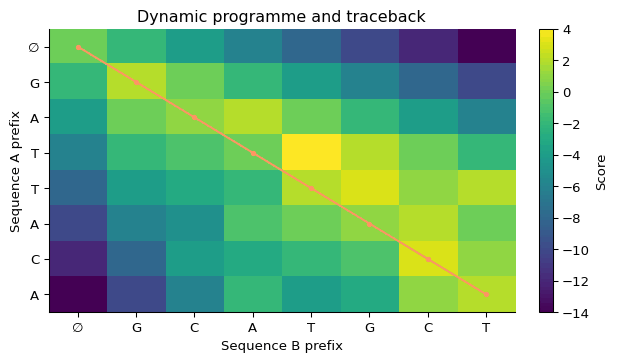

In [2]:
a, b = ("GATTACA", "GCATGCU".replace("U", "T"))
score, left, right, matrix, path = dp_align(a, b, local=False)
check = PairwiseAligner(
    mode="global", match_score=2, mismatch_score=-1, open_gap_score=-2, extend_gap_score=-2
)
print(left)
print(right)
print("Traceback score", score, "| independent score", check.score(a, b))
assert score == check.score(a, b)
show_dp(a, b, matrix, path)
plt.show()

## Interpreting the result

Read the path from its first to its last cell. A horizontal or vertical run is a gap. The colouring shows why several routes can have the same score.

## Exercise

Force a long unmatched prefix into one input. Compare its effect on the local and global objectives.

## References

[Needleman and Wunsch, global alignment (1970)](https://doi.org/10.1016/0022-2836(70)90057-4)

[Biopython, pairwise alignments](https://biopython.org/docs/latest/Tutorial/chapter_pairwise.html)